In [1]:
# Attention: ASVI8 and ASVI4 from Google Trends (Section 3.2.1)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The clean files are saved straight into the folder with the regression notebooks
OUT = "../Regressions and relevant csvs/"

In [2]:
# Google Trends search volume (SVI) for "AI Stocks", United States, all categories, web search,
# monthly, April 2015 to December 2025, downloaded with pytrends on March 4, 2026.
# Google Trends draws a new sample of searches for every request, so a new download gives slightly
# different numbers. The thesis therefore uses the saved download (see the README for how it was saved).
#
# Code used for the download:
# from pytrends.request import TrendReq
# pytrends = TrendReq(hl="en-US", tz=360)
# pytrends.build_payload(kw_list=["AI Stocks"], cat=0, timeframe="2015-04-01 2025-12-31", geo="US", gprop="")
# svi = pytrends.interest_over_time().drop(columns="isPartial")

svi = pd.read_csv("AIStocks_SVI_raw.csv")
svi["date"] = pd.to_datetime(svi["month"]) + pd.offsets.MonthEnd(0)
svi = svi[["date", "SVI"]].sort_values("date").reset_index(drop=True)
svi.tail()

,date,SVI
124,2025-08-31,100
125,2025-09-30,79
126,2025-10-31,74
127,2025-11-30,74
128,2025-12-31,69


In [3]:
# ASVI = log(SVI) - log(median SVI of the previous w months), w = 8 (main measure) or 4 (robustness)
def asvi(series, window):
    series = series.astype(float).replace(0, 0.5)               # log(0) is undefined
    past_median = series.rolling(window).median().shift(1)      # months t-w to t-1
    return np.log(series) - np.log(past_median)

svi["ASVI8"] = asvi(svi["SVI"], 8)
svi["ASVI4"] = asvi(svi["SVI"], 4)

# Thesis sample: December 2015 to December 2025 (121 months)
attention = svi[svi["date"] >= "2015-12-31"].reset_index(drop=True)
attention.head(12)

,date,SVI,ASVI8,ASVI4
0,2015-12-31,0,0.0,0.0
1,2016-01-31,0,0.0,0.0
2,2016-02-29,0,0.0,0.0
3,2016-03-31,0,0.0,0.0
4,2016-04-30,0,0.0,0.0
5,2016-05-31,0,0.0,0.0
6,2016-06-30,0,0.0,0.0
7,2016-07-31,0,0.0,0.0
8,2016-08-31,0,0.0,0.0
9,2016-09-30,0,0.0,0.0


In [4]:
# Numbers mentioned in the text
s = attention.set_index("date")
print("Months with SVI = 0:", (s["SVI"] == 0).sum())
print("Months with SVI <= 2:", (s["SVI"] <= 2).sum())
print("Highest SVI before 2023:", s.loc[:"2022-12-31", "SVI"].max())
print("First month with SVI above 5:", s.index[s["SVI"] > 5][0].strftime("%B %Y"))
print("Months with ASVI8 = 0:", (s["ASVI8"] == 0).sum())
print(f"ASVI8 peak: {s['ASVI8'].max():.2f} in {s['ASVI8'].idxmax():%B %Y}")
print(f"ASVI8 minimum: {s['ASVI8'].min():.2f}")

Months with SVI = 0: 17
Months with SVI <= 2: 78
Highest SVI before 2023: 5
First month with SVI above 5: February 2023
Months with ASVI8 = 0: 48
ASVI8 peak: 2.40 in February 2023
ASVI8 minimum: -0.69


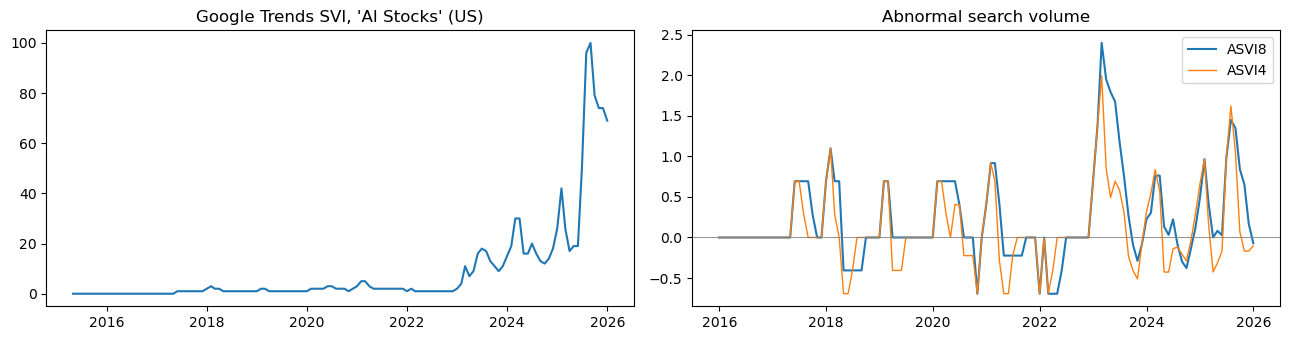

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(svi["date"], svi["SVI"])
axes[0].set_title("Google Trends SVI, 'AI Stocks' (US)")
axes[1].plot(attention["date"], attention["ASVI8"], label="ASVI8")
axes[1].plot(attention["date"], attention["ASVI4"], lw=1, label="ASVI4")
axes[1].axhline(0, color="grey", lw=0.6)
axes[1].set_title("Abnormal search volume")
axes[1].legend()
plt.tight_layout()
plt.show()

In [6]:
attention[["date", "ASVI8"]].to_csv(OUT + "AIStocks_ASVI8_Monthly.csv", index=False)
attention[["date", "ASVI4"]].to_csv(OUT + "AIStocks_ASVI4_Monthly.csv", index=False)
attention[["date", "SVI"]].to_csv(OUT + "AIStocks_SVI_Monthly.csv", index=False)   # for Figure A.1